# Part B: Smoothing, windows and panel shape, computed (15 marks)

Works on the cleaned daily sessions series from Part D. The cleaning is repeated in one cell so this notebook runs on its own.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from vizlib import PALETTE, style_defaults, save_fig   # Week 3 toolkit
import tslib                                           # Week 4 toolkit

%matplotlib inline
style_defaults()

DATA = Path("data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def save(fig, name, note=None):
    """fig.savefig first (300 dpi, tight), THEN the figure is shown."""
    save_fig(fig, FIG / name, note)

def check(label, ok, detail=""):
    print(f"[{'PASS' if ok else 'FAIL'}] {label} {detail}")
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
def load_clean():
    """Same cleaning as Part D (step-by-step version is in part_d.ipynb)."""
    log = []
    df = pd.read_csv(DATA / "sessions_hourly.csv")
    iso = df.ts.str.contains("-")                      # ISO rows vs dd/mm/yyyy rows
    t = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
    t[iso] = pd.to_datetime(df.ts[iso], format="%Y-%m-%d %H:%M:%S")
    t[~iso] = pd.to_datetime(df.ts[~iso], format="%d/%m/%Y %H:%M")
    log.append(("parse slash rows as dd/mm/yyyy", int((~iso).sum())))
    df["t"] = t
    df = df.drop(columns="ts")
    log.append(("device case normalised", int((df.device != df.device.str.strip().str.title()).sum())))
    df["device"] = df.device.str.strip().str.title()
    n = len(df); df = df.drop_duplicates(); log.append(("exact duplicate rows dropped", n - len(df)))
    df = df.set_index("t").sort_index()
    log.append(("sessions == -1 sentinel -> NaN", int((df.sessions == -1).sum())))
    df["sessions"] = df.sessions.where(df.sessions != -1)
    full = pd.date_range(df.index.min(), df.index.max(), freq="h")
    log.append(("hours never recorded (reindexed)", len(full) - len(df)))
    hourly = df.reindex(full); hourly.index.name = "t"
    daily = hourly.sessions.resample("D").sum(min_count=1)   # sessions is a flow: sum
    log.append(("whole days with no data (NaN)", int(daily.isna().sum())))
    return hourly, daily, log

hourly, daily, log = load_clean()
filled = daily.interpolate(limit_direction="both")     # ONLY for decompose / lag / grid. Marked here.
print(f"series {daily.index.min().date()} to {daily.index.max().date()}, {int(daily.isna().sum())} NaN days interpolated for Q3-Q5 only")
log

series 2024-04-01 to 2025-09-11, 13 NaN days interpolated for Q3-Q5 only


[('parse slash rows as dd/mm/yyyy', 3651),
 ('device case normalised', 1447),
 ('exact duplicate rows dropped', 286),
 ('sessions == -1 sentinel -> NaN', 287),
 ('hours never recorded (reindexed)', 312),
 ('whole days with no data (NaN)', 13)]

## Q1. The window is a hypothesis (4 marks)
`window_report` for 7, 28 and 91: the cycle each removes, the share of raw variation removed, the periods lost at each end.

In [3]:
wr = tslib.window_report(filled, (7, 28, 91))
wr

,window,raw_sd,smoothed_sd,variation_removed_pct,periods_lost_each_end
0,7,6753.2516,4638.1749,31.3,3
1,28,6753.2516,4420.1756,34.5,14
2,91,6753.2516,4139.0151,38.7,45


**My answer:**

| window | cycle it removes | raw variation removed | periods lost each end |
|---|---|---|---|
| 7 | the weekly cycle exactly (one full period) | 31.3% | 3 |
| 28 | the weekly cycle (4 full periods) plus fortnight-to-month wobble | 34.5% | 14 |
| 91 | weekly plus anything shorter than a quarter | 38.7% | 45 |

The three numbers are close (31% → 39%). The 7-day window already cancels the weekly cycle, whose peak-to-trough amplitude is 7,352 sessions a day (Q3). Quadrupling the window to 28 days adds only 3 points, and 91 days adds 4 more, while costing 14 and 45 days at each end. What survives any window is the slow part: the monthly mean climbs from 15,000 (Apr 2024) to 29,300 (Nov 2024), falls to 22,400 (Apr 2025) and climbs again. That is trend and yearly rhythm, which is the story, so no window should remove it. **For Part D I will use the 7-day window**, because 7 is the period of the cycle I want to cancel: each window then holds exactly one Saturday, one Sunday and so on, and the weekend bump (+5,000) cancels. It is not chosen for smoothness. A 28-day window would also cancel it (28 = 4×7) but would smear the Black Friday event across a month and lose 14 days at each end for no extra cancelling.

## Q2. Three smoothers against one spike (3 marks)

In [4]:
d = pd.Timestamp("2024-11-29")
mean = filled.rolling(14, center=True, min_periods=7).mean().loc[d]
med = filled.rolling(14, center=True, min_periods=7).median().loc[d]
ewma = filled.ewm(span=14, min_periods=7).mean().loc[d]
print(f"raw {filled.loc[d]:,.0f} | 14d centred mean {mean:,.0f} | median {med:,.0f} | EWMA(span=14) {ewma:,.0f}")

raw 113,710 | 14d centred mean 32,871 | median 24,698 | EWMA(span=14) 37,537


**My answer:** On 29 Nov 2024 the raw value is 113,710. The 14-day centred **mean** is 32,871, the **median** is 24,698 and the **EWMA** (span 14) is 37,537. The fortnight median is about 24,600, so the median is the only one of the three that is not dragged by the spike: the mean is pulled up by about 8,200 and the EWMA by about 12,800. The EWMA is the highest because it is trailing and keeps remembering the spike for weeks afterwards.

- **Monitoring dashboard: EWMA, drawn under the raw line.** It is trailing, so it exists for today with no future data (a centred window cannot), and it reacts at once, which is what a monitor is for. Its weakness, staying inflated after a spike, is acceptable on a dashboard where the raw spike is also visible.
- **Quarterly report: the 14-day centred median.** It reports the typical level (24,698) instead of letting one-off Black Friday raise a whole month of the line by 8,000 to 13,000 sessions, and no future-data constraint applies to a finished quarter. Black Friday is then annotated as its own event rather than smoothed into the baseline.

## Q3. Decompose it (3 marks)

weekly seasonal peak-to-trough amplitude: 7,352 sessions/day
largest residual on 2024-11-29 (value 75,072)


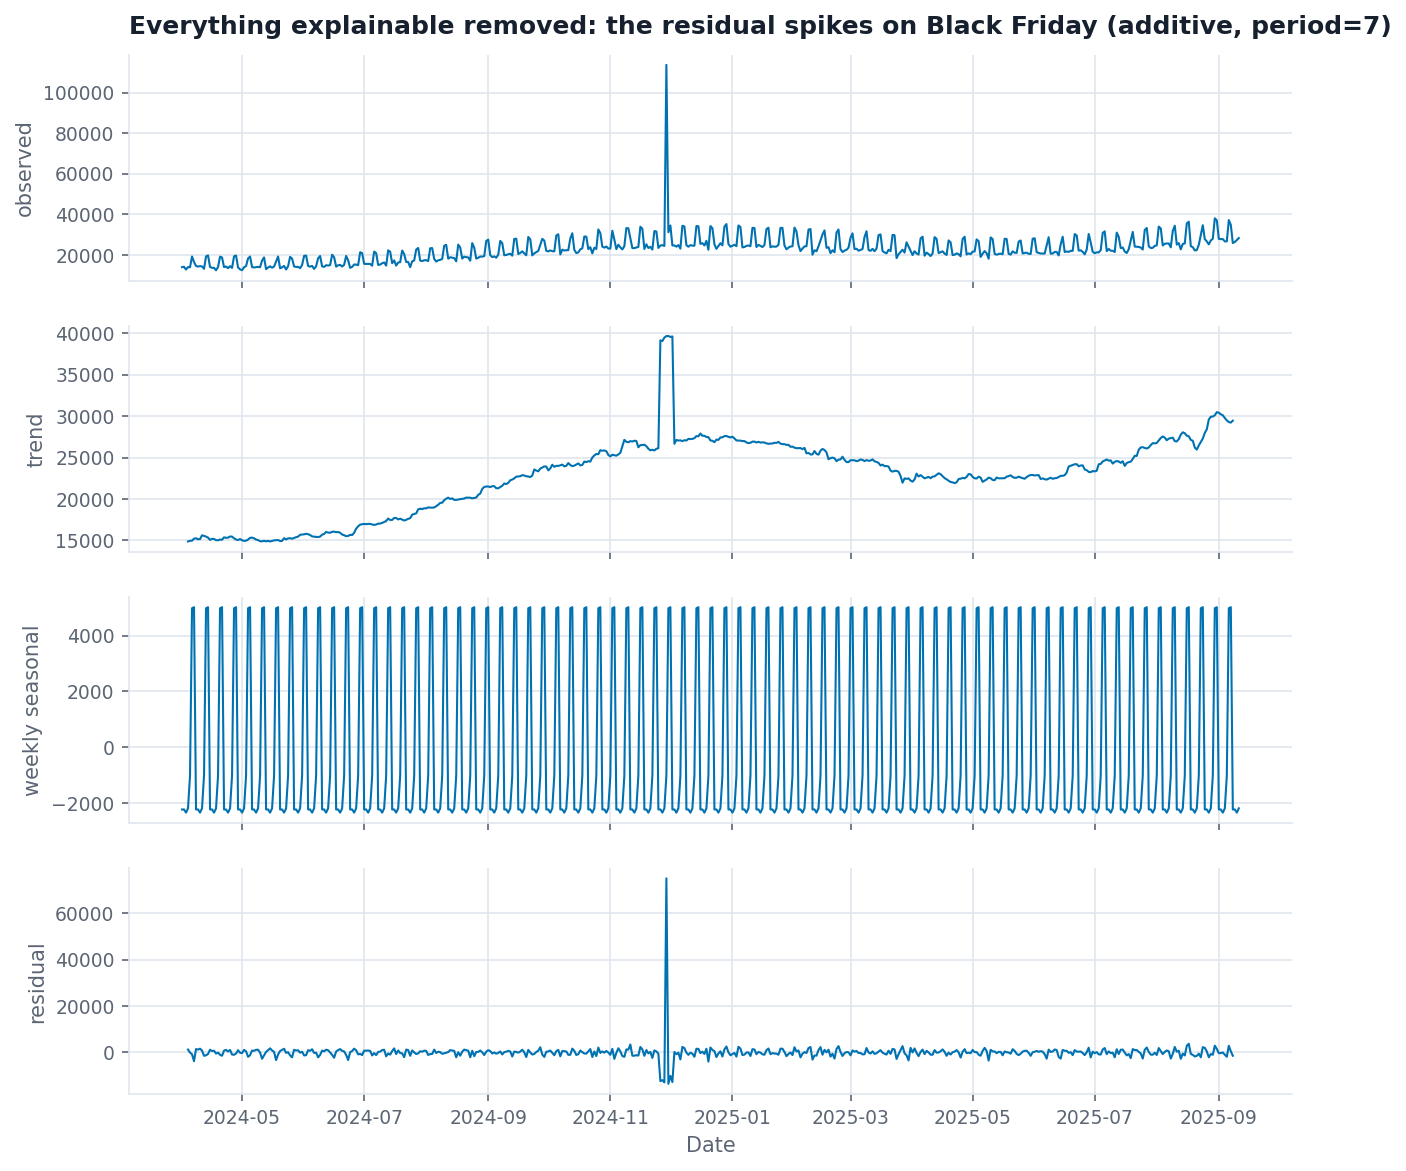

In [5]:
r = seasonal_decompose(filled, model="additive", period=7)
seas = r.seasonal.iloc[:7]
big = r.resid.abs().idxmax()
print(f"weekly seasonal peak-to-trough amplitude: {seas.max() - seas.min():,.0f} sessions/day")
print(f"largest residual on {big.date()} (value {r.resid.loc[big]:,.0f})")
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax_, comp, name in zip(axes, [r.observed, r.trend, r.seasonal, r.resid], ["observed", "trend", "weekly seasonal", "residual"]):
    ax_.plot(comp.index, comp, color=PALETTE["series"][0], linewidth=1); ax_.set_ylabel(name)
axes[0].set_title("Everything explainable removed: the residual spikes on Black Friday (additive, period=7)")
axes[-1].set_xlabel("Date")
save(fig, "part_b_decompose.png"); plt.show()

In [6]:
try:
    seasonal_decompose(filled, model="additive", period=365)
except ValueError as e:
    print("period=365 failed:", e)
    print(f"the series has {len(filled)} days; two full yearly cycles need 730")

period=365 failed: x must have 2 complete cycles requires 730 observations. x only has 529 observation(s)
the series has 529 days; two full yearly cycles need 730


**My answer:** The weekly seasonal component has a peak-to-trough amplitude of **7,352 sessions a day** (weekdays about −2,200, Saturday +4,975, Sunday +5,013). The largest residual is **29 Nov 2024 (Black Friday), +75,072**. The next-largest residuals are only about 13,000 (30 Nov, 28 Nov, 2 Dec, all of them the shoulders of the same event), so this one day is the single thing left unexplained once trend and week are removed, and so it is the event worth investigating.

`period=365` cannot run: the series has **529 days** and the function needs two complete cycles (730). Had it been able to run, what would move from `resid` into `seasonal` is whatever recurs every year: the late-November shopping uplift (Nov 2024 averages 29,300 against 24,400 in Oct) would be assigned to the yearly seasonal instead of being left as residual. With only one Black Friday on record you could never separate a yearly pattern from a one-off, which is why the function refuses.

## Q4. Trailing or centred (2 marks)

In [7]:
lg = tslib.lag_at_turn(filled, 31)
print(f"trailing turn {lg['trailing_turn'].date()} | centred turn {lg['centred_turn'].date()} | "
      f"lag {lg['lag_periods']} days | half-window {lg['half_window']}")

trailing turn 2024-05-30 | centred turn 2024-05-15 | lag 15 days | half-window 15


**My answer:** Trailing turn 30 May 2024, centred turn 15 May 2024: the lag is **15 days, exactly the half-window (31 // 2 = 15)**. A trailing mean at day t averages the 31 days that end at t, so it is centred 15 days in the past and cannot see a turn until the window has filled. That is arithmetic, not a bug.

A morning-refresh dashboard has to show the **trailing** mean: a centred mean needs 15 days of data that do not exist yet, so its last 15 points would be missing or silently shrunk. The caption must say so: *"31-day trailing mean: turning points appear about 15 days after they happen."* Add the day the turn was first visible, not the day it started.

## Q5. The window is a claim (3 marks)
**Definition I used:** for each of 12 start months (the first 12 month-starts of the series) and 5 window lengths, take the series from that start to the end, smooth with a *trailing* rolling mean of that length, fit a straight line, read the sign of the slope.

In [8]:
first = filled.index.min().to_period("M").to_timestamp()
starts = pd.date_range(first, periods=12, freq="MS")
rows = []
for st in starts:
    for w in (7, 14, 28, 56, 91):
        sm = filled.loc[st:].rolling(w).mean().dropna()
        slope = np.polyfit(np.arange(len(sm)), sm.to_numpy(), 1)[0]
        rows.append({"start": st.date(), "window": w, "slope": slope})
grid = pd.DataFrame(rows)
print(f"combinations: {len(grid)} | rising: {(grid.slope > 0).sum()} | falling: {(grid.slope < 0).sum()}")
grid.pivot(index="start", columns="window", values="slope").round(1)

combinations: 60 | rising: 37 | falling: 23


window,7,14,28,56,91
start,,,,,
2024-04-01,20.6,20.3,19.6,18.4,16.8
2024-05-01,18.6,18.1,17.1,15.0,12.4
2024-06-01,15.2,14.4,12.9,9.8,6.2
2024-07-01,10.6,9.6,7.6,3.8,-0.7
2024-08-01,5.0,3.9,1.6,-3.0,-8.2
2024-09-01,-0.4,-1.7,-4.4,-9.4,-15.1
2024-10-01,-4.8,-6.2,-9.1,-14.5,-17.7
2024-11-01,-8.0,-9.4,-12.2,-13.7,-15.7
2024-12-01,-1.3,-2.2,-3.7,-6.0,-7.4


**My answer:** Of the 60 combinations (12 start months × 5 windows), **37 give a rising trend and 23 a falling one**. The window length hardly matters; the start month decides. Starting April–June 2024 or January 2025 onward, every window gives a rise; starting September–December 2024, every window gives a fall; only the July and August 2024 starts flip sign with the window (July: −0.7 at 91 days, +10.6 at 7; August: −3.0 at 56 days, +5.0 at 7). The slopes range from −17.7 to +31.7 sessions per day per day. The same series supports "growing" or "declining" depending on where the chart begins, and each such chart is arithmetically correct.

**Why the Lie Factor cannot be computed here.** LF = (effect shown in the graphic) / (effect in the data). The denominator assumes there is one effect *in the data*: a single, window-independent start and end that exist before the chart is drawn. Here there is no such thing: the data contain 60 different effects with opposite signs. If I treat the cherry-picked window as "the data", the graphic's effect equals the data's effect by construction and LF = 1.00, an honest-looking score for a misleading chart. The distortion is in the choice of frame, which is not ink that can be measured against anything.

**The honest substitute** is to measure sensitivity to the choice instead: fix the window by a rule stated before looking (the full series, or the same months in the previous year), and report how often the conclusion survives the alternatives, here "37 of 60 windows rise, 23 fall, and the sign depends on the start month". Show the full grid or the full series with the chosen window marked, and put both counts in the caption.